In [1]:
# Import and Job
from pathlib import Path
import joblib

import traceback
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import shap
from lime.lime_tabular import LimeTabularExplainer

model_path = Path(
    r"C:\Users\cgqua\Downloads\KevsAndEricka\mlops_deployment\ai_engineering_portfolio\projects\explainable-iris\src\models\iris_random_forest.joblib")

model = joblib.load(model_path)

In [2]:
# Iris Load Dataset
iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
class_names = list(iris.target_names)

In [3]:
#Train and Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


FEATURE IMPORTANCE

Which measurements influence the model most?
          Feature Importance
 petal width (cm)     0.4372
petal length (cm)     0.4315
sepal length (cm)     0.1163
 sepal width (cm)     0.0150


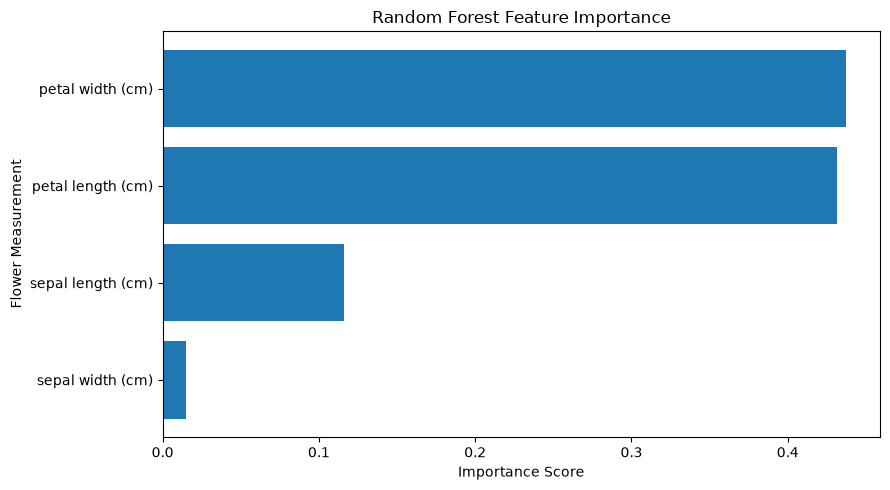

In [4]:
#Feature Importance with GRAPH
print("\n" + "=" * 65)
print("FEATURE IMPORTANCE")
print("=" * 65)

#Data Formatting exclude the data type
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
}).sort_values(
    by="Importance", 
    ascending=False)

print("\nWhich measurements influence the model most?")

#Print and Data Output
print(importance_df.to_string(
    index=False,
    formatters={"Importance": "{:.4f}".format}
))

# First Graph
plt.figure(figsize=(9,5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Flower Measurement")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [5]:
# Predict An Example Flower

sample_index = 0 #This selects the first flower in X_test. 
#It does not select the first flower in the original dataset.
#That's an important comment you correctly added.

sample = X_test[sample_index].reshape(1, -1) #The model expects input 
#shaped like a table with one row and four columns.
#That's an important comment you correctly added.
#[5.1, 3.5, 1.4, 0.2]
#4 values

actual_species = class_names[y_test[sample_index]] #This retrieves the 
#known label from the testing data so you can compare it with the 
# model's prediction.
#y_test[sample_index]
#0/setosa

predicted_class = int(model.predict(sample)[0])
predicted_species = class_names[predicted_class]

# model.predict(sample) returns a numerical class, 
# such as 0, 1, or 2. class_names converts that number into a
# readable species name.

probabilities = model.predict_proba(sample)[0]


In [6]:
#Sample Prediction

("\n" + "=" * 65)
print("SAMPLE PREDICTION")
print("=" * 65)

print("\nFlower Measurements:") #sepal and petal length and width

for name, value in zip(feature_names, sample[0]):
    print(f"{name}: {value:.2f} cm")

print(f"\nActual Species: {actual_species}")
print(f"\nPrediction Species: {predicted_species}")

print("\nPrediction Probabilities:") # Kung what kind flower if setosa, versicolor and virginica

for species, probability in zip(class_names, probabilities):
    print(f"{species}: {probability:.2%}")

SAMPLE PREDICTION

Flower Measurements:
sepal length (cm): 4.40 cm
sepal width (cm): 3.00 cm
petal length (cm): 1.30 cm
petal width (cm): 0.20 cm

Actual Species: setosa

Prediction Species: setosa

Prediction Probabilities:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%



SHAP EXPLAINABILITY

Calculating SHAP Values

Global SHAP feature importance
          Feature Mean Absolute SHAP Value
 petal width (cm)                  0.20224
petal length (cm)                  0.19886
sepal length (cm)                  0.04276
 sepal width (cm)                  0.00482


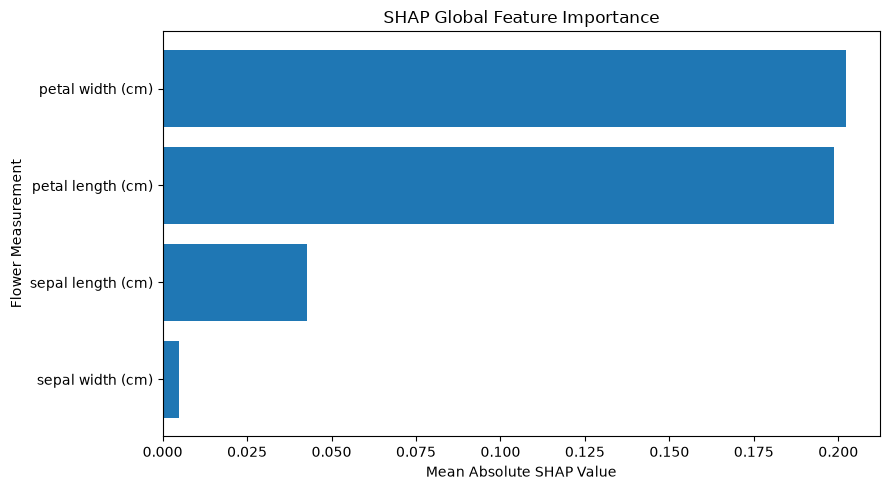


SHAP Explanation for the sample prediction:
          Feature Measurement (cm) SHAP Value
 petal width (cm)             0.20    0.29688
petal length (cm)             1.30    0.28385
sepal length (cm)             4.40    0.08929
 sepal width (cm)             3.00   -0.00019


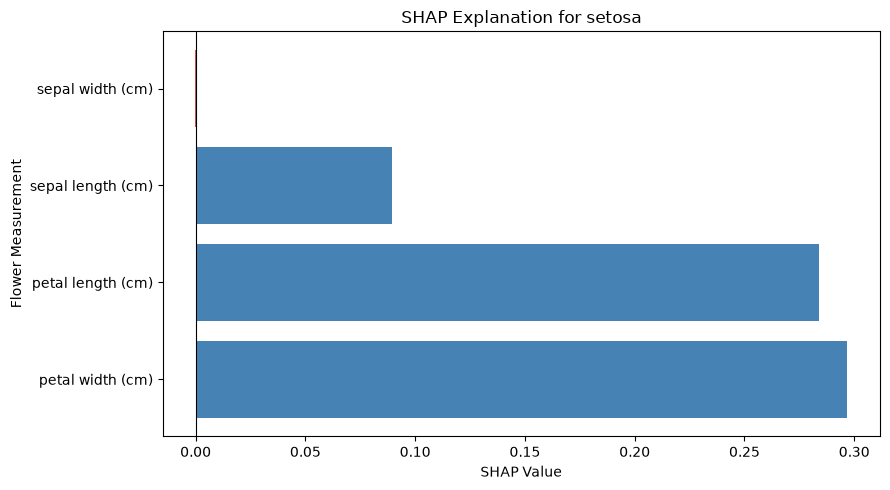


SHAP interpretation:
- Larger absolute SHAP values indicate stronger contributions.
- Positive and negative values are relative to the
- selected class's model output.
- SHAP values explain the model; they do not prove causation


In [7]:
print("\n"+ "=" * 65)
print("SHAP EXPLAINABILITY")
print("=" * 65)

print("\nCalculating SHAP Values")

try:
    # TreeExplainer is designed for tree based models.
    """
    "I have a tree-based model. Please create an explainer appropriate for this model."
    Since Random Forest consists of decision trees, TreeExplainer is appropriate.
    """
    shap_explainer = shap.TreeExplainer(model)
    """
    SHAP examines the test samples and calculates how each feature contributes to the model output.
    """
    shap_result = shap_explainer(X_test) # gamitin ung sa sample test and contains 30 test samples and 4 features
    
    shap_values = np.asarray(shap_result.values) # This makes the SHAP output easier for your code to process.
    #shap_result.values contains the actual SHAP values
    #You're converting them into a NumPy array.

    """
    SHAP output maybe:
    2D: sample x features
    3D: sample x features x classes

    If SHAP returns two-dimensional values instead, 
    your code uses a separate branch:

    global_importance = np.abs(shap_values).mean(axis=0)

    The resulting DataFrame is sorted to show which measurements
    have the greatest average contribution to the model's output.
    
    For three-dimensional SHAP values, this selects the 
    contributions for the chosen flower and its predicted species.

    if shap_values.ndim == 3: = bali lalabas ang "petal width (cm) 0.20224" so on and so forth

    SHAP's output format can vary depending on the SHAP/model/version combination.

    samples × features × classes

    30 × 4 × 3

    30 test flowers
    4 measurements
    3 species

    shap_values = np.asarray(shap_result.values)
       
    shap_result.values

    np.asarray(...)

    shap_values

    
    This makes it easier to perform operations such as:

    np.abs()
    .mean()

    and to check:
    shap_values.ndim

    
    
    1D = ndim = 1

    [1, 2, 3, 4]


    2D = ndim = 2

    [
        [1, 2, 3, 4],
        [5, 6, 7, 8]
    ]

    3D = ndim = 3

    Sample
      ↓
    Feature
      ↓
    Class

    SHAP values

Sample 1
 ├── Sepal Length
 │    ├── Setosa
 │    ├── Versicolor
 │    └── Virginica
 │
 ├── Sepal Width
 │    ├── Setosa
 │    ├── Versicolor
 │    └── Virginica
 │
 └── ...
    """

    if shap_values.ndim == 3: # Ndim means number of dimensions of an array and tells you how many axes/dimensions the data has.
        global_importance = np.abs(shap_values).mean(axis=(0,2))

        """
        "Across all test samples and all classes, which features have the strongest SHAP contribution?"
        
        np.abs(shap_values)

        -0.50 → 0.50
        +0.30 → 0.30
        -0.10 → 0.10

        Why?

        Because global importance is interested in magnitude, not direction.

        A SHAP value of: -0.8 and +0.8 is also a strong contribution


        mean(axis=(0,2))

        shap_values.shape = (30, 4, 3) which means:

        axis 0 → samples, axis 1 → features and axis 2 → classes, and you want to keep the features.

        So you average across: axis=0 and axis=2, and the output is 4

        30 samples
        ↓
        average
        ↓
        4 features
        ↑
        average
        ↑
        3 classes

        Sepal Length     0.31
        Sepal Width      0.14
        Petal Length     0.72
        Petal Width      0.64
        """

        
        
        #Below is for local explanation, give me the SHAP values for this particular flower and the class that the model predicted
        """
        - sample_index = 5 as an example means "Explain test flower #5."

        - colon means give me all features (all 4 measurements)

        - predicted_class = 2 (Which species/class) might correspond to Virginica, depending on your class encoding

        Explanation: So this entire statement means: Give me all feature contributions for this specific flower toward the predicted species.
 
        """

        sample_shap = shap_values[
            sample_index, 
            :, 
            predicted_class
        ]


        """
        For below: 2

        Now suppose SHAP returns: (30, 4) instead of (30, 4, 3) = samples × features

        global_importance = np.abs(shap_values).mean(axis=0) means: Take the absolute SHAP values and average them across all samples.

        axis 0 = samples and axis 1 = features, average over the samples and keep the features.

        sample_shap = shap_values[sample_index] means get the SHAP values for the selected sample.

        For example: sample_index = 5 and might give [0.12, -0.03, 0.71, 0.42] one value for each feature

        """

    elif shap_values.ndim == 2:
        global_importance = np.abs(shap_values).mean(axis=0)
        sample_shap = shap_values[sample_index]
    
    else:
        raise ValueError(
            f"Unexpected Output Shape: {shap_values.shape}"
        )

    # Global

    shap_importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Mean Absolute SHAP Value": global_importance
    }).sort_values(by="Mean Absolute SHAP Value", ascending=False)

    print("\nGlobal SHAP feature importance")

    # "{:.5f}".format - display the number with 5 digits after the decimal point. Example is 0.20224

    print(shap_importance_df.to_string(
        index=False,
        formatters={"Mean Absolute SHAP Value": "{:.5f}".format}
    ))

    #Second Graph
    plt.figure(figsize=(9,5)) # 9 inches wide and 5 inches tall

    plt.barh( # H means horizontal bar
        shap_importance_df["Feature"],#yaxis
        shap_importance_df["Mean Absolute SHAP Value"]#xaxis
    )

    
    plt.xlabel("Mean Absolute SHAP Value")
    plt.ylabel("Flower Measurement")
    plt.title("SHAP Global Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    
    
    # Local

    local_shap_df = pd.DataFrame({
        "Feature": feature_names,
        "Measurement (cm)": sample[0],
        "SHAP Value": sample_shap
    })

    #Absolute Local

    local_shap_df["Absolute SHAP"] = (
        local_shap_df["SHAP Value"].abs()
    )

    #Sort Local

    local_shap_df = local_shap_df.sort_values(
        by = "Absolute SHAP",
        ascending=False
    )

    print("\nSHAP Explanation for the sample prediction:")

    # Output Local

    print(local_shap_df[
        ["Feature", "Measurement (cm)", "SHAP Value"]
    ].to_string(
        index=False,
        formatters={
            "Measurement (cm)": "{:.2f}".format,
            "SHAP Value": "{:.5f}".format
        }
    ))


    # Third Graph

    plt.figure(figsize=(9,5))

    #Color Declaration
    bar_colors=[
        "steelblue" if value >=0 else "indianred"
        for value in local_shap_df["SHAP Value"]#Name ng pang declare and output
    ]

    plt.barh(
        local_shap_df["Feature"], #y
        local_shap_df["SHAP Value"], #x
        color=bar_colors
    )

    plt.axvline(0, color="black", linewidth=0.8) #Extra line sa loob ng graph
    plt.xlabel("SHAP Value")
    plt.ylabel("Flower Measurement")
    plt.title(f"SHAP Explanation for {predicted_species}")
    plt.tight_layout()
    plt.show()

    print("\nSHAP interpretation:")
    print("- Larger absolute SHAP values indicate stronger contributions.")
    print("- Positive and negative values are relative to the")
    print("- selected class's model output.")
    print("- SHAP values explain the model; they do not prove causation")


except Exception as error:
    print("\n SHAP explanation could not be completed.")
    print(f"Reason: {error}")
    print("Check that the SHAP and Numpy versions are compatible")


LIME EXPLAINABILITY

LIME Explanation for the selected flower:
petal length (cm) <= 1.60: 0.43446
petal width (cm) <= 0.30: 0.43351
sepal length (cm) <= 5.10: 0.02950
2.80 < sepal width (cm) <= 3.00: -0.00547


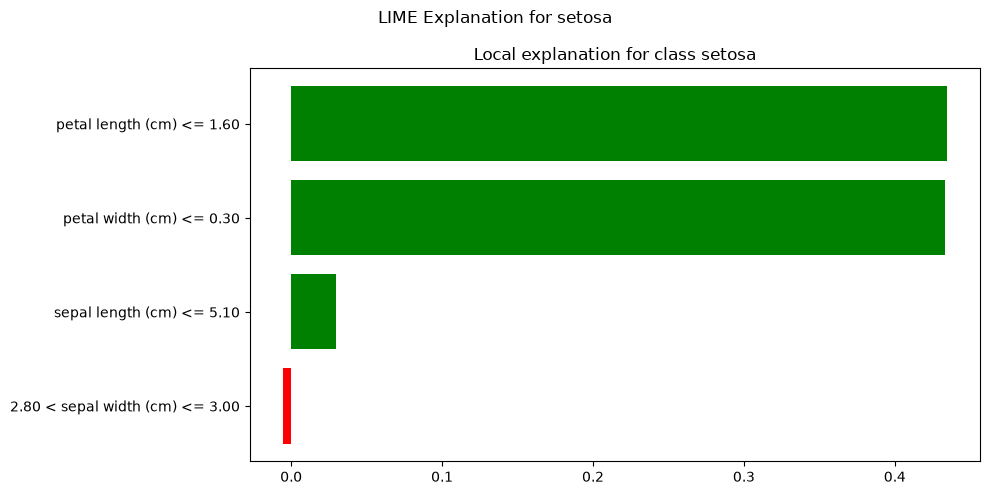


 LIME Interpretation:
- LIME Approximates the model around 1 selected sample.
- Positive Contributions support the explained class.
- Negative Contributions oppose that class locally.


In [ ]:
print("\n" + "=" * 65)
print("LIME EXPLAINABILITY")
print("=" * 65)

lime_explainer = None # There is currently no value/object assigned.

# Below is the variable will contain your actual LIME explainer

"""
try
 │
 ├── Create LIME explainer
 ├── Explain sample
 ├── Print results
 └── Create graph
      │
      ▼
   If error
      │
      ▼
except
"""



"""
lime_explainer = LimeTabularExplainer


"Here is the training data, here are the feature names and class names, my model performs classification, and I want LIME to explain individual predictions."

training_data=X_train = training dataset (If you have 120 training samples and 4 features)

X_train
        │
        ├── Sepal Length
        ├── Sepal Width
        ├── Petal Length
        └── Petal Width

X_train.shape ((120, 4))

LIME uses this training data to understand what normal/typical feature values look like.

This is important because LIME will generate artificial samples around the flower you're trying to explain.
"""

try:
    lime_explainer = LimeTabularExplainer(
        training_data=X_train,
        feature_names=feature_names, # Sepal Length and others
        class_names=class_names, # setosa and others
        mode="classification", # Random Forest is predicting a species/class rather than a continuous number
        # Input -> Flower measurements -> Random Forest -> Predicted class ->  Virginica 
        # If regression problem, you would choose mode="regression"   
        discretize_continuous=True, # continuous numerical measurements, LIME can turn continuous values into ranges/intervals.
        # For example, instead of simply saying: Petal Length = 5.4
        # LIME might create a rule such as: Petal Length > 4.8 or Petal Width > 1.7 
        # and This makes LIME's explanation easier for humans to read.
        # Output: Petal length > 4.8: 0.42, Petal width > 1.6: 0.31 and Sepal width <= 3.0: -0.05
        random_state=42 # LIME uses randomness when generating samples around the flower. If use again, I may get the same explanation.
    )

#"Explain why the model made this prediction for this particular flower."
    lime_explanation = lime_explainer.explain_instance(
        data_row=sample[0], # This is the specific flower you want LIME to explain.
        # sample[0] - could be: [6.2, 3.4, 5.4, 2.3]
        # Sepal Length = 6.2
        # Sepal Width  = 3.4 
        # Petal Length = 5.4
        # Petal Width  = 2.3
        predict_fn=model.predict_proba, # You're giving LIME the model's probability prediction function.
        # Instead of only asking - model.predict(sample) which might return Virginica, 
        # I'm only asking model.predict_proba(sample)
        # Setosa      0.01, Versicolor 0.05 and Virginica  0.94  
        labels=(predicted_class,), # This tells LIME which class you want to explain. Explanation
        # Suppose: predicted_class = 2 / 2 = Virginica -- 
        # Then you're saying: "Explain class 2, which is Virginica." 
        # (2,) is a tuple containing one item, (2) is simply the number 2
        num_features=len(feature_names), # 4 because of Sepal and Petal Width and Length
        num_samples=3000 # Generate/use 3,000 perturbed samples around the selected flower to understand the model's local behavior.
        # Generally, more samples can give LIME a more stable local approximation, but it also takes more computation.
    )

    print("\nLIME Explanation for the selected flower:")

    """
    This converts the LIME explanation into a list of: rule + contribution

=================================================================
LIME EXPLAINABILITY
=================================================================

LIME Explanation for the selected flower:
petal length (cm) <= 1.60: -rule 0.43446 - contribution
petal width (cm) <= 0.30: 0.43351
sepal length (cm) <= 5.10: 0.02950
2.80 < sepal width (cm) <= 3.00: -0.00547
    """
    lime_results = lime_explanation.as_list( # To Output the Petal and Sepal Width and Length as show above as list
        label=predicted_class
    )

    for rule, contribution in lime_results: # Print the mentioned above
        print(f"{rule}: {contribution:.5f}")


    figure = lime_explanation.as_pyplot_figure( # Make as graph above
        label=predicted_class
    )

    figure.set_size_inches(10,5)
    figure.suptitle(
        f"LIME Explanation for {predicted_species}"
    )

    plt.tight_layout()
    plt.show()


    print("\n LIME Interpretation:")
    print("- LIME Approximates the model around 1 selected sample.")
    print("- Positive Contributions support the explained class.")
    print("- Negative Contributions oppose that class locally.")

except Exception as error:
    print("\nLIME Explanation could not be completed")
    print(f"Reason: {error}")


CUSTOM IRIS FLOWER PREDICTION

Enter Flower Measurement in Centimeters.
Expected ranges are approximately:
Sepal Length: 4.3 to 7.9:
Sepal Width: 2.0 to 4.4:
Petal Length: 1.0 to 6.9:
Petal Width: 0.1 to 2.5:

Prediction Result:
Predicted Species: virginica

Prediction Probabilities
setosa: 2.00%
versicolor: 28.00%
virginica: 70.00%

CUSTOM IRIS PREDICTION
Predicted species:  virginica

Prediction Probabilities:
setosa:2.00%
versicolor:28.00%
virginica:70.00%

Generating LIME Explanation


LIME Explaination for your flower:
petal width (cm) > 1.80: 0.41348
1.60 < petal length (cm) <= 4.25: -0.13278
sepal length (cm) <= 5.10: 0.04522
sepal width (cm) <= 2.80: 0.00574


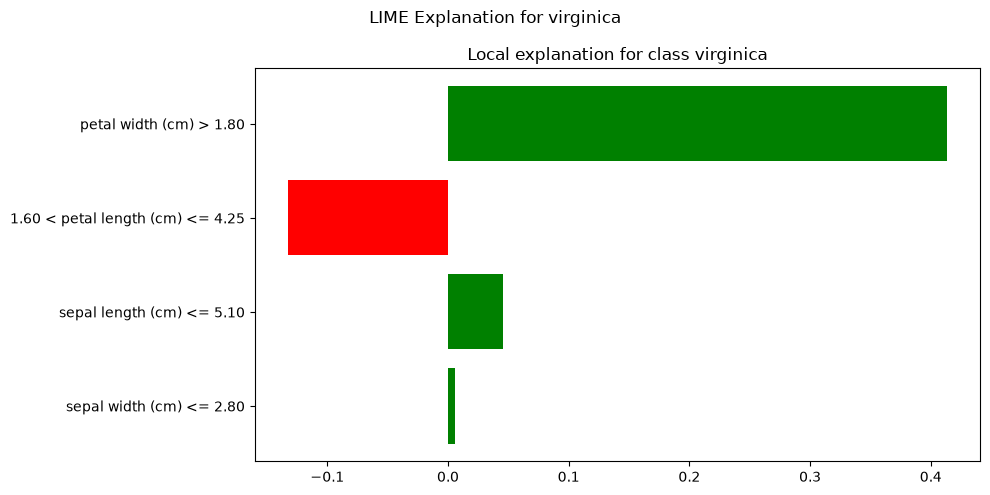


LIME Interpretation:
- Positive contributions support the explained class locally
- Negative contributions oppose the explained class locally
- LIME explains the model's local behavior;it does not provide causation

Program Completed. Thank you!

End of XAI Iris Projects


In [ ]:
"""
User enters measurements
        ↓
Validate measurements
        ↓
Create NumPy array
        ↓
Random Forest prediction
        ↓
Prediction probabilities
        ↓
Check if LIME is available
        ↓
Generate LIME explanation
        ↓
Display LIME rules + graph
        ↓
Ask user if they want another prediction
"""





print("\n" + "=" * 65)
print("CUSTOM IRIS FLOWER PREDICTION")
print("=" * 65)

print("\nEnter Flower Measurement in Centimeters.")
print("Expected ranges are approximately:")
print("Sepal Length: 4.3 to 7.9:")
print("Sepal Width: 2.0 to 4.4:")
print("Petal Length: 1.0 to 6.9:")
print("Petal Width: 0.1 to 2.5:")

"""

while True
    │
    ├── Ask user
    │
    ├── Predict
    │
    ├── Explain
    │
    └── Ask again

"""

while True:
    choice = input(
        "\nWould you like to predict your own flower? (y/n)"
    ).strip().lower() #para maging lower lang and removes unnecessary spaces

    if choice == "n":
        print("\nProgram Completed. Thank you!")
        break

    if choice != "y":
        print("Please enter y or n.")
        continue

    try:
        measurements = [] # This creates an empty Python list.

        for feature in feature_names: # Sepal and Petal Width and Length and the value should be float
            value = float(
                input(f"Enter {feature} in cm:")
            )

            # need mag ka error pag di finite and zero values ang input

            if not np.isfinite(value):
                raise ValueError(
                    "Measurements must be finite numbers."
                )

            if value <=0 :
                raise ValueError(
                    "Measurements must be greater than zero."
                )

            measurements.append(value) # Add the measurement to the list

        # Convert measurements into a NumPy array

        """
        Initially you have: [6.2, 3.4, 5.4, 2.3]

        Its shape is: (4,)

        But scikit-learn expects prediction input in the form: (number of samples, number of features)

        So you need: (1, 4) meaning 1 flower and 4 features

        .reshape(1, -1) - 1 → I want 1 row/sample and -1 → Python should automatically determine the number of columns

        I get: [6.2, 3.4, 5.4, 2.3]

        Shape: (1, 4)

        So: 1 = one flower and 4 = four measurements, This is the format your Random Forest expects.
        """

        new_flower = np.array(
            measurements,
            dtype=float
        ).reshape(1,-1)



        new_prediction = int(model.predict(new_flower)[0]) # same as predicted_class but a new pred
        
        new_probabilities = model.predict_proba(new_flower)[0] # same as predicted_species but a new prob

        print("\nPrediction Result:")
        print(f"Predicted Species: {class_names[new_prediction]}") # New flower is setosa and others

        print("\nPrediction Probabilities") # ilabas lahat ng flowers and kung ano kung pinaka mataas na values
        # edi yun ang flower na un

        for species, probability in zip(
            class_names,
            new_probabilities
        ):

            print(f"{species}: {probability:.2%}")


        """
        Check whether LIME is available - if lime_explainer is not None:

        lime_explainer = None and lime_explainer = LimeTabularExplainer(...)

        if LIME initialization succeeded so this condition asks:
        
        Do we have a working LIME explainer?" If yes: Continue with LIME explanation

        If no: Skip LIME and This is good defensive programming.

        """ 

        if lime_explainer is not None:
            try:
                custom_input = np.asarray(
                    new_flower,
                    dtype=float
                ).reshape(1,len(feature_names)) # ung sa may new flower, ung reshape is reshape(1,-1)

                print("\n" + "=" * 65)
                print("CUSTOM IRIS PREDICTION")
                print("=" * 65)

                print(
                    f"Predicted species: " # flower name same as new_prediction above
                    f" {class_names[new_prediction]}" 
                )

                print("\nPrediction Probabilities:") # flower name same as new_probabilities above

                for class_index, probability in enumerate(
                    new_probabilities
                ):
                    print(
                        f"{class_names[class_index]}:"
                        f"{probability:.2%}"
                    )

                print("\nGenerating LIME Explanation")

                new_explanation = lime_explainer.explain_instance( # same as nauna na dahil ito ay input

                    data_row = custom_input[0],
                    predict_fn=model.predict_proba,
                    labels=(new_prediction,),
                    num_features=len(feature_names),
                    num_samples=1000
                )

                print("\n" + "=" * 65)
                print("\nLIME Explaination for your flower:")
                print("=" * 65)

                lime_results = new_explanation.as_list(
                    label=new_prediction
                )

                for rule, contribution in lime_results:
                    print(f"{rule}: {contribution:.5f}")

                new_figure = new_explanation.as_pyplot_figure(
                    label=new_prediction
                )

                new_figure.set_size_inches(10,5)

                new_figure.suptitle(
                    f"LIME Explanation for "
                    f"{class_names[new_prediction]}"
                )

                new_figure.tight_layout()
                plt.show()
                plt.close(new_figure)

                print("\nLIME Interpretation:")
                print(
                    "- Positive contributions support the "
                    "explained class locally"
                )
                print(
                    "- Negative contributions oppose the "
                    "explained class locally"
                )
                print(
                    "- LIME explains the model's local behavior;"
                    "it does not provide causation"
                )

            except Exception as error:
                print("\nLIME Explanation failed!")
                print(f"Error type: {type(error).__name__}")
                print(f"Error details: {error}")

                traceback.print_exc()

        else:
            print(
                "\nLIME Explainer is unavailable. "
                "The flower prediction was completed, "
                "but its LIME Explanation cannot be generated."
            )

    except ValueError as error: # pag mali ang input
        print(f"\nInvalid input: {error}")
        print("Please try again with valid numeric measurements")

    except Exception as error: # pag nag fail ang prediction
        print(f"\nPrediction failed: {error}")

print("\nEnd of XAI Iris Projects")